# DAIN on FI-2010: reproduction notebook
Challa Umesh Varun (230318), EE798R

Everything behind my report is in here: data, the DAIN layer + baselines, training, all 90 runs, the results table
and the plots.

Training everything takes ~1 hour on my laptop GPU (RTX 3050), so finished runs get saved in `runs/own/` and are
just loaded next time. Flip `RETRAIN = True` if you want to train from scratch. (GPU runs aren't bit-for-bit
repeatable, so a retrained run can move by a few tenths of a point.)

Data: `data/lob.h5`, the preprocessed FI-2010 file from https://github.com/passalis/dain

## Setup

In [1]:
import json
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score, precision_recall_fscore_support

ROOT = Path.cwd()
RUNS = ROOT / "runs" / "own"
RUNS.mkdir(parents=True, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
RETRAIN = False

# settings from the paper (MLP experiments)
WINDOW, BATCH, EPOCHS, LR = 15, 128, 20, 1e-4
SUB_LR = (1e-6, 1e-3, 10.0)   # lr multipliers for shift / scale / gate
SPLITS, SEEDS = (0, 1, 2), (0, 1, 2)

METHODS = ["none", "zscore", "avg", "bn", "in", "dain1", "dain2", "dain3", "dain12", "dain123"]
NAMES = {"none": "No normalisation", "zscore": "z-score", "avg": "Sample average", "bn": "Batch Norm.",
         "in": "Instance Norm.", "dain1": "DAIN (1)", "dain2": "DAIN (2)", "dain3": "DAIN (3)",
         "dain12": "DAIN (1+2)", "dain123": "DAIN (1+2+3)"}

# paper, Table I (MLP): F1 mean, F1 sd, kappa
PAPER = {"none": (12.71, 13.22, 0.0010), "zscore": (53.76, 0.99, 0.3059), "avg": (41.80, 3.58, 0.1915),
         "bn": (52.72, 1.94, 0.2893), "in": (59.13, 2.94, 0.3717), "dain1": (57.37, 3.16, 0.3536),
         "dain12": (66.71, 2.02, 0.4896), "dain123": (66.92, 1.70, 0.4934)}

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print(DEV, torch.__version__)

cuda 2.6.0+cu124


## Data
144 raw features per snapshot (first 40 = price/volume of the 10 ask and bid levels). Labels: 0 up, 1 stationary,
2 down. Walk-forward split k trains on days 1..k+1 and tests on day k+2; I use the first three splits like Table I.

In [2]:
with h5py.File(ROOT / "data" / "lob.h5", "r") as f:
    X = torch.from_numpy(f["features"][:]).to(DEV)
    Y = torch.from_numpy(f["targets"][:].astype(np.int64)).to(DEV)
    TRAIN_IDX = f["day_train_split_idx"][:].astype(bool)
    TEST_IDX = f["day_test_split_idx"][:].astype(bool)
    STOCK = f["stock_idx"][:].astype(bool)

print(X.shape)   # should be 453975 x 144, same as the paper
y0 = Y[:, 0].cpu().numpy()
print("up / stationary / down %:", np.round(100 * np.bincount(y0) / len(y0), 1))

torch.Size([453975, 144])
up / stationary / down %: [ 5.1 89.6  5.3]


In [3]:
def windows(mask):
    # per stock: rows j-15..j-1 are the input, label comes from row j (same as the authors' loader)
    W, L, S = [], [], []
    for s in range(STOCK.shape[0]):
        rows = np.where(mask & STOCK[s])[0]
        n = len(rows) - WINDOW - 1
        if n <= 0:
            continue
        j = np.arange(WINDOW, WINDOW + n)
        W.append(rows[j[:, None] - WINDOW + np.arange(WINDOW)[None, :]])
        L.append(rows[j])
        S.append(np.full(n, s))
    return (torch.from_numpy(np.concatenate(W)).to(DEV), torch.from_numpy(np.concatenate(L)).to(DEV),
            np.concatenate(S))


for s in SPLITS:
    print(f"split {s}: {len(windows(TRAIN_IDX[s])[1])} train / {len(windows(TEST_IDX[s])[1])} test windows")

split 0: 46847 train / 44619 test windows
split 1: 91546 train / 33225 test windows
split 2: 124851 train / 42757 test windows


## Model
DAIN has three stages, each can be switched on separately:
shift $x - W_a \bar x$, scale (divide by $W_b \cdot$ rms of the window), gate (multiply by
$\sigma(W_c \bar x + d)$). $W_a$, $W_b$ start as identity. Besides the paper's (1), (1+2), (1+2+3) I also try
(2) and (3) on their own.

In [4]:
DAIN_STAGES = {"dain1": {1}, "dain12": {1, 2}, "dain123": {1, 2, 3}, "dain2": {2}, "dain3": {3}}


class DAIN(nn.Module):
    def __init__(self, stages, d=144, eps=1e-8):
        super().__init__()
        self.stages, self.eps = set(stages), eps
        self.shift = nn.Linear(d, d, bias=False)
        self.scale = nn.Linear(d, d, bias=False)
        nn.init.eye_(self.shift.weight)
        nn.init.eye_(self.scale.weight)
        self.gate = nn.Linear(d, d)

    def forward(self, x):  # x: (batch, 144, 15)
        if 1 in self.stages:
            x = x - self.shift(x.mean(2)).unsqueeze(2)
        if 2 in self.stages:
            beta = self.scale(torch.sqrt((x ** 2).mean(2) + self.eps))
            beta = torch.where(beta <= self.eps, torch.ones_like(beta), beta)
            x = x / beta.unsqueeze(2)
        if 3 in self.stages:
            x = x * torch.sigmoid(self.gate(x.mean(2))).unsqueeze(2)
        return x


class InputNorm(nn.Module):
    # zscore is done on the data itself before training, so here it (and "none") is just identity
    def __init__(self, method):
        super().__init__()
        self.method = method
        if method == "bn":
            self.layer = nn.BatchNorm1d(144)
        elif method == "in":
            self.layer = nn.InstanceNorm1d(144)
        elif method.startswith("dain"):
            self.layer = DAIN(DAIN_STAGES[method])

    def forward(self, x):
        if self.method == "avg":
            return x - x.mean(2, keepdim=True)
        if self.method in ("none", "zscore"):
            return x
        return self.layer(x)


class Net(nn.Module):
    def __init__(self, method):
        super().__init__()
        self.norm = InputNorm(method)
        self.head = nn.Sequential(nn.Linear(144 * WINDOW, 512), nn.ReLU(), nn.Dropout(0.5), nn.Linear(512, 3))

    def forward(self, x):  # x: (batch, 15, 144)
        return self.head(self.norm(x.transpose(1, 2)).flatten(1))


print(sum(p.numel() for p in Net("dain123").norm.parameters()), "DAIN params,",
      sum(p.numel() for p in Net("none").head.parameters()), "MLP params")

62352 DAIN params, 1107971 MLP params


## Training
RMSprop, lr 1e-4, batch 128, 20 epochs. Batches are sampled with weight 1/(class size) so up/down aren't drowned out
by the ~90% stationary windows. Each DAIN stage gets its own lr (base lr x multiplier).

In [5]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=float((y == p).mean()), precision=float(pr), recall=float(rc), f1=float(f1),
                kappa=float(cohen_kappa_score(y, p)))


@torch.no_grad()
def predict(net, Xs, Wi):
    net.eval()
    out = torch.cat([net(Xs[Wi[i:i + 4096]]).argmax(1) for i in range(0, len(Wi), 4096)])
    net.train()
    return out.cpu().numpy()


def run(method, split, seed, tag_extra=""):
    tag = f"{method}_mlp_s{split}_h0_seed{seed}{tag_extra}"
    if (RUNS / f"{tag}.json").exists() and not RETRAIN:   # already done -> just load it
        return json.loads((RUNS / f"{tag}.json").read_text())

    t0 = time.time()
    torch.manual_seed(seed)
    Wtr, Ltr, _ = windows(TRAIN_IDX[split])
    Wte, Lte, ste = windows(TEST_IDX[split])
    Xs = X
    if method == "zscore":   # mean/std from the training days only
        rows = torch.from_numpy(np.where(TRAIN_IDX[split])[0]).to(DEV)
        Xs = (X - X[rows].mean(0)) / (X[rows].std(0, unbiased=False) + 1e-15)
    ytr, yte = Y[Ltr, 0], Y[Lte, 0]

    net = Net(method).to(DEV)
    groups = [{"params": [p for n, p in net.named_parameters() if not n.startswith("norm.layer.")]}]
    if method.startswith("dain"):
        a, b, c = SUB_LR
        lay = net.norm.layer
        groups += [{"params": lay.shift.parameters(), "lr": LR * a},
                   {"params": lay.scale.parameters(), "lr": LR * b},
                   {"params": lay.gate.parameters(), "lr": LR * c}]
    elif method == "bn":
        groups += [{"params": net.norm.layer.parameters()}]
    opt = torch.optim.RMSprop(groups, lr=LR)
    lossf = nn.CrossEntropyLoss()

    w = (1.0 / torch.bincount(ytr, minlength=3).float())[ytr]
    gen = torch.Generator(device=DEV).manual_seed(seed)
    curve = []
    for ep in range(EPOCHS):
        idx = torch.multinomial(w, len(ytr), replacement=True, generator=gen)
        tot = torch.zeros((), device=DEV)
        for b in idx.split(BATCH):
            loss = lossf(net(Xs[Wtr[b]]), ytr[b])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.detach() * len(b)
        curve.append(float(tot) / len(idx))

    pred = predict(net, Xs, Wte)
    y = yte.cpu().numpy()
    res = dict(method=method, model="mlp", split=split, hcol=0, seed=seed, n_train=len(ytr), n_test=len(y),
               **metrics(y, pred), seconds=round(time.time() - t0, 1), curve=curve,
               per_stock={int(s): metrics(y[ste == s], pred[ste == s]) for s in np.unique(ste)})
    if method.startswith("dain"):   # how far did the shift/scale weights move from identity?
        eye = torch.eye(144, device=DEV)
        res["dW_shift"] = float((net.norm.layer.shift.weight - eye).abs().max())
        res["dW_scale"] = float((net.norm.layer.scale.weight - eye).abs().max())
    if tag_extra == "_fig":
        torch.save(net.state_dict(), RUNS / f"{tag}.pt")
    np.savez_compressed(RUNS / f"{tag}.npz", y=y, pred=pred, stock=ste, label_row=Lte.cpu().numpy())
    (RUNS / f"{tag}.json").write_text(json.dumps(res))
    return res

## All runs: 10 methods x 3 splits x 3 seeds

In [6]:
t0 = time.time()
R = {(m, s, sd): run(m, s, sd) for m in METHODS for s in SPLITS for sd in SEEDS}
print(len(R), "runs,", round(time.time() - t0), "s")
print("avg train time per run:", round(np.mean([r["seconds"] for r in R.values()]) / 60, 1), "min")

90

 runs, 0 s
avg train time per run: 0.8 min


## Results
Mean over the 9 runs; the +- is the sd across the 3 splits (that's how the paper reports it).

In [7]:
F1 = {m: np.array([[100 * R[(m, s, sd)]["f1"] for sd in SEEDS] for s in SPLITS]) for m in METHODS}  # split x seed
KAPPA = {m: np.mean([R[(m, s, sd)]["kappa"] for s in SPLITS for sd in SEEDS]) for m in METHODS}

rows = []
for m in METHODS:
    p = PAPER.get(m)
    rows.append({"method": NAMES[m],
                 "paper F1": f"{p[0]:.2f} +- {p[1]:.2f}" if p else "--",
                 "my F1": f"{F1[m].mean():.2f} +- {F1[m].mean(1).std(ddof=1):.2f}",
                 "paper kappa": f"{p[2]:.4f}" if p else "--",
                 "my kappa": f"{KAPPA[m]:.4f}"})
pd.DataFrame(rows).set_index("method")

,paper F1,my F1,paper kappa,my kappa
method,,,,
No normalisation,12.71 +- 13.22,12.92 +- 0.26,0.0010,0.0002
z-score,53.76 +- 0.99,51.41 +- 2.23,0.3059,0.2718
Sample average,41.80 +- 3.58,49.91 +- 6.53,0.1915,0.2512
Batch Norm.,52.72 +- 1.94,52.42 +- 1.82,0.2893,0.2856
Instance Norm.,59.13 +- 2.94,58.38 +- 3.70,0.3717,0.3597
DAIN (1),57.37 +- 3.16,57.38 +- 4.82,0.3536,0.3576
DAIN (2),--,52.00 +- 2.48,--,0.2877
DAIN (3),--,9.62 +- 5.87,--,0.0000
DAIN (1+2),66.71 +- 2.02,66.15 +- 2.40,0.4896,0.4816


In [8]:
def paired(a, b):
    d = F1[a] - F1[b]   # same split + seed, so the comparison is paired
    return f"{d.mean():+.1f} +- {d.mean(1).std(ddof=1) / np.sqrt(3):.1f}  ({(d > 0).sum()}/9 runs better)"


checks = [("dain123", "zscore", "DAIN vs z-score"), ("dain123", "in", "DAIN vs instance norm"),
          ("dain12", "dain1", "+ scale on top of shift"), ("dain123", "dain12", "+ gate"),
          ("dain1", "avg", "DAIN(1) vs sample avg"), ("dain2", "zscore", "scale only vs z-score"),
          ("dain2", "in", "scale only vs instance norm"), ("dain12", "dain2", "+ shift in front of scale"),
          ("dain3", "none", "gate only vs nothing")]
for a, b, label in checks:
    print(f"{label:28s} {paired(a, b)}")

DAIN vs z-score              +14.9 +- 0.7  (9/9 runs better)
DAIN vs instance norm        +7.9 +- 0.8  (9/9 runs better)
+ scale on top of shift      +8.8 +- 1.6  (9/9 runs better)
+ gate                       +0.1 +- 0.2  (4/9 runs better)
DAIN(1) vs sample avg        +7.5 +- 1.0  (8/9 runs better)
scale only vs z-score        +0.6 +- 0.2  (6/9 runs better)
scale only vs instance norm  -6.4 +- 0.9  (0/9 runs better)
+ shift in front of scale    +14.1 +- 0.5  (9/9 runs better)
gate only vs nothing         -3.3 +- 3.2  (1/9 runs better)


Quick sanity check: with lr 1e-4 x 1e-6 the shift weights should basically not move. Also checking what DAIN(3)
actually predicts.

In [9]:
print("max |W_a - I|, full DAIN:", max(R[("dain123", s, sd)]["dW_shift"] for s in SPLITS for sd in SEEDS))
print("max |W_b - I|, full DAIN:", max(R[("dain123", s, sd)]["dW_scale"] for s in SPLITS for sd in SEEDS))
print("max |W_b - I|, DAIN(2):  ", max(R[("dain2", s, sd)]["dW_scale"] for s in SPLITS for sd in SEEDS))

counts = [np.bincount(np.load(RUNS / f"dain3_mlp_s{s}_h0_seed{sd}.npz")["pred"], minlength=3)
          for s in SPLITS for sd in SEEDS]
print(f"DAIN(3): at least {100 * min(c.max() / c.sum() for c in counts):.2f}% of windows get the same class in each run")
picked = [int(c.argmax()) for c in counts]
print("DAIN(3) runs stuck on up / stationary / down:", [picked.count(c) for c in (0, 1, 2)])

max |W_a - I|, full DAIN: 2.019833971189655e-07
max |W_b - I|, full DAIN: 0.0002713799476623535
max |W_b - I|, DAIN(2):   0.0006022874149493873
DAIN(3): at least 99.96% of windows get the same class in each run
DAIN(3) runs stuck on up / stationary / down: [3, 2, 4]


## Plots

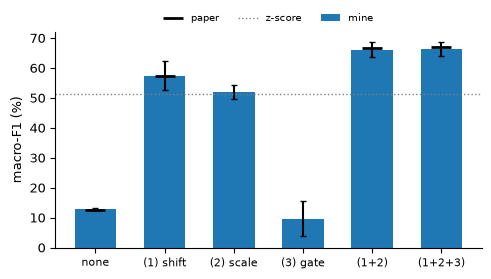

In [10]:
ms = ["none", "dain1", "dain2", "dain3", "dain12", "dain123"]
x = np.arange(len(ms))
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.bar(x, [F1[m].mean() for m in ms], 0.6, yerr=[F1[m].mean(1).std(ddof=1) for m in ms], capsize=2, label="mine")
idx = [i for i, m in enumerate(ms) if m in PAPER]
ax.plot(idx, [PAPER[ms[i]][0] for i in idx], "k_", ms=14, mew=2, ls="none", label="paper")
ax.axhline(F1["zscore"].mean(), color="0.5", ls=":", lw=1, label="z-score")
ax.set_xticks(x)
ax.set_xticklabels(["none", "(1) shift", "(2) scale", "(3) gate", "(1+2)", "(1+2+3)"], fontsize=8)
ax.set_ylabel("macro-F1 (%)")
ax.legend(frameon=False, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.show()

Why fixed normalisation struggles here: the 5 stocks sit at very different price levels and drift over the 10 days.

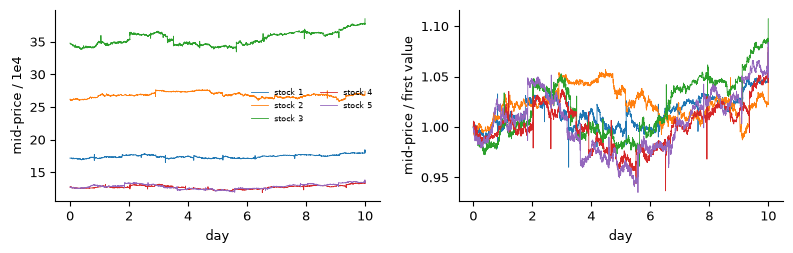

In [11]:
Xn = X.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6))
for k in range(STOCK.shape[0]):
    rows = np.where(STOCK[k])[0]
    mid = (Xn[rows, 0] + Xn[rows, 2]) / 2
    days = np.linspace(0, 10, len(rows))
    axes[0].plot(days, mid / 1e4, lw=0.6, label=f"stock {k + 1}")
    axes[1].plot(days, mid / mid[0], lw=0.6)
axes[0].set_ylabel("mid-price / 1e4")
axes[1].set_ylabel("mid-price / first value")
for ax in axes:
    ax.set_xlabel("day")
axes[0].legend(frameon=False, fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

Confusion matrices (all splits and seeds added up, rows normalised). Shift seems to be what gets the direction right,
scale cuts down the false alarms. DAIN(3) just predicts one class per run, so its rows look the same.

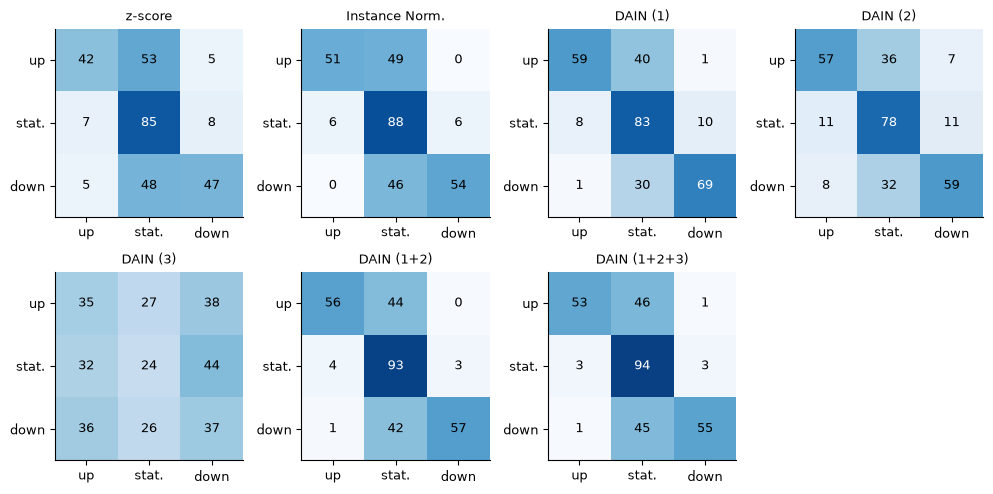

z-score          caught  44.6% | called stationary  50.2% | wrong way  5.2% | stationary ok  84.6%
Instance Norm.   caught  52.2% | called stationary  47.6% | wrong way  0.3% | stationary ok  88.0%
DAIN (1)         caught  63.8% | called stationary  35.2% | wrong way  1.0% | stationary ok  82.6%
DAIN (2)         caught  58.1% | called stationary  34.2% | wrong way  7.7% | stationary ok  78.3%
DAIN (3)         caught  36.2% | called stationary  26.6% | wrong way 37.1% | stationary ok  23.8%
DAIN (1+2)       caught  56.2% | called stationary  43.1% | wrong way  0.7% | stationary ok  92.8%


DAIN (1+2+3)     caught  54.1% | called stationary  45.3% | wrong way  0.6% | stationary ok  93.6%


In [12]:
def confusion(m):
    C = sum(confusion_matrix(np.load(RUNS / f"{m}_mlp_s{s}_h0_seed{sd}.npz")["y"],
                             np.load(RUNS / f"{m}_mlp_s{s}_h0_seed{sd}.npz")["pred"], labels=[0, 1, 2])
            for s in SPLITS for sd in SEEDS).astype(float)
    return 100 * C / C.sum(1, keepdims=True)


shown = ["zscore", "in", "dain1", "dain2", "dain3", "dain12", "dain123"]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes[1, 3].axis("off")
for ax, m in zip(axes.ravel(), shown):
    C = confusion(m)
    ax.imshow(C, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{C[i, j]:.0f}", ha="center", va="center", color="w" if C[i, j] > 60 else "k")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(["up", "stat.", "down"])
    ax.set_yticklabels(["up", "stat.", "down"])
    ax.set_title(NAMES[m], fontsize=9)
plt.tight_layout()
plt.show()

for m in shown:
    C = confusion(m)
    hit, miss = (C[0, 0] + C[2, 2]) / 2, (C[0, 1] + C[2, 1]) / 2
    flip = (C[0, 2] + C[2, 0]) / 2
    print(f"{NAMES[m]:16s} caught {hit:5.1f}% | called stationary {miss:5.1f}% | wrong way {flip:4.1f}% "
          f"| stationary ok {C[1, 1]:5.1f}%")

Looking inside one trained full-DAIN model (split 2, seed 0; I kept its weights).

F1 of this run: 69.2%
mean gate -> prices 0.35, volumes 0.97, derived 0.74
15 of 144 features get shifted by more than their own spread


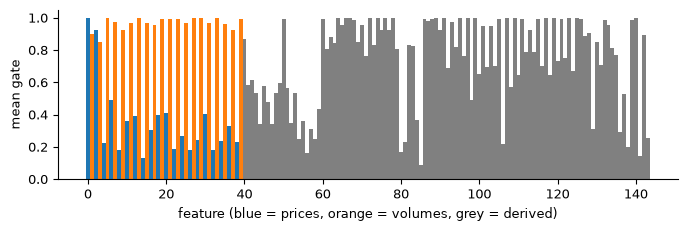

In [13]:
fig_run = run("dain123", 2, 0, tag_extra="_fig")
net = Net("dain123").to(DEV)
net.load_state_dict(torch.load(RUNS / "dain123_mlp_s2_h0_seed0_fig.pt", map_location=DEV))
net.eval()
Wte, Lte, ste = windows(TEST_IDX[2])
lay = net.norm.layer

with torch.no_grad():
    x = X[Wte[:20000]].transpose(1, 2)
    x1 = x - lay.shift(x.mean(2)).unsqueeze(2)
    beta = lay.scale(torch.sqrt((x1 ** 2).mean(2) + lay.eps))
    x2 = x1 / torch.where(beta <= lay.eps, torch.ones_like(beta), beta).unsqueeze(2)
    gate = torch.sigmoid(lay.gate(x2.mean(2))).mean(0).cpu().numpy()
    # how big is the shift caused by W_a - I compared to each feature's own spread?
    a = x.mean(2)
    ratio = ((lay.shift(a) - a).abs() / (x.std(2) + 1e-12)).median(0).values.cpu().numpy()

print(f"F1 of this run: {100 * fig_run['f1']:.1f}%")
print(f"mean gate -> prices {gate[0:40:2].mean():.2f}, volumes {gate[1:40:2].mean():.2f}, derived {gate[40:].mean():.2f}")
print((ratio > 1).sum(), "of 144 features get shifted by more than their own spread")

colors = ["C0" if i < 40 and i % 2 == 0 else "C1" if i < 40 else "0.5" for i in range(144)]
fig, ax = plt.subplots(figsize=(8, 2.2))
ax.bar(np.arange(144), gate, color=colors, width=1.0)
ax.set_xlabel("feature (blue = prices, orange = volumes, grey = derived)")
ax.set_ylabel("mean gate")
plt.show()

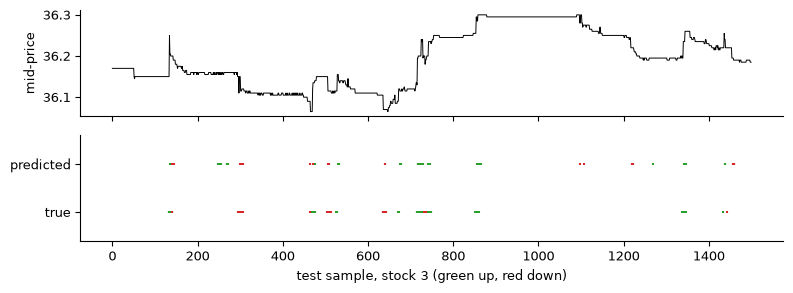

In [14]:
# one test day for the stock with the most windows
z = np.load(RUNS / "dain123_mlp_s2_h0_seed0_fig.npz")
k = int(np.argmax(np.bincount(ste)))
sel = np.where(z["stock"] == k)[0][:1500]
rows = z["label_row"][sel]
mid = (Xn[rows, 0] + Xn[rows, 2]) / 2 / 1e4

fig, axes = plt.subplots(2, 1, figsize=(8, 3), sharex=True)
axes[0].plot(mid, lw=0.7, color="k")
axes[0].set_ylabel("mid-price")
for r, lab in enumerate([z["y"][sel], z["pred"][sel]]):
    for c, col in [(0, "C2"), (2, "C3")]:
        t = np.where(lab == c)[0]
        axes[1].scatter(t, np.full(len(t), r), s=2, color=col, marker="|")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["true", "predicted"])
axes[1].set_ylim(-0.6, 1.6)
axes[1].set_xlabel(f"test sample, stock {k + 1} (green up, red down)")
plt.tight_layout()
plt.show()

Where does it fail? Per stock, by how volatile the window is, and by time of day.

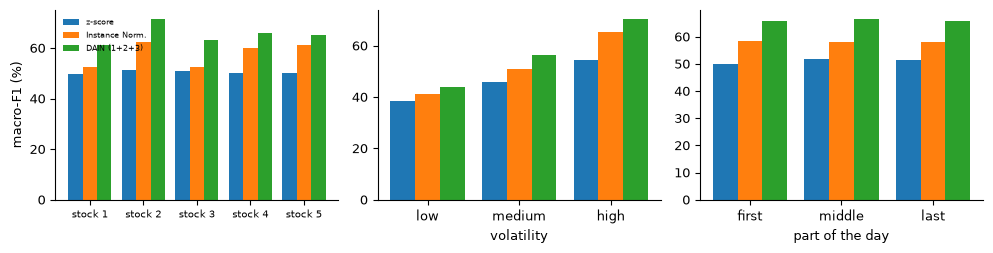

DAIN F1 by volatility (low, mid, high): [43.7, 56.5, 70.4]


In [15]:
mid_all = (Xn[:, 0] + Xn[:, 2]) / 2
compare = ["zscore", "in", "dain123"]
by_vol = {m: [[], [], []] for m in compare}
by_time = {m: [[], [], []] for m in compare}
per_stock = {m: np.zeros(5) for m in compare}

for s in SPLITS:
    Wt, _, st = windows(TEST_IDX[s])
    vol = np.diff(np.log(mid_all[Wt.cpu().numpy()]), axis=1).std(1)
    vq = np.digitize(vol, np.quantile(vol, [1 / 3, 2 / 3]))   # volatility terciles
    tod = np.zeros(len(st), int)                               # first / middle / last third of the day
    for k in np.unique(st):
        i = np.where(st == k)[0]
        tod[i] = np.minimum(3 * np.arange(len(i)) // len(i), 2)
    for m in compare:
        for sd in SEEDS:
            z = np.load(RUNS / f"{m}_mlp_s{s}_h0_seed{sd}.npz")
            for g in range(3):
                by_vol[m][g].append(100 * f1_score(z["y"][vq == g], z["pred"][vq == g], average="macro"))
                by_time[m][g].append(100 * f1_score(z["y"][tod == g], z["pred"][tod == g], average="macro"))
            per_stock[m] += [100 * R[(m, s, sd)]["per_stock"][str(q)]["f1"] for q in range(5)]
for m in compare:
    per_stock[m] /= 9

fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for i, m in enumerate(compare):
    off = (i - 1) * 0.27
    axes[0].bar(np.arange(5) + off, per_stock[m], 0.27, label=NAMES[m])
    axes[1].bar(np.arange(3) + off, [np.mean(v) for v in by_vol[m]], 0.27)
    axes[2].bar(np.arange(3) + off, [np.mean(v) for v in by_time[m]], 0.27)
axes[0].set_xticks(range(5))
axes[0].set_xticklabels([f"stock {q + 1}" for q in range(5)], fontsize=7)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(["low", "medium", "high"])
axes[1].set_xlabel("volatility")
axes[2].set_xticks(range(3))
axes[2].set_xticklabels(["first", "middle", "last"])
axes[2].set_xlabel("part of the day")
axes[0].set_ylabel("macro-F1 (%)")
axes[0].legend(frameon=False, fontsize=6)
plt.tight_layout()
plt.show()

print("DAIN F1 by volatility (low, mid, high):", [round(float(np.mean(v)), 1) for v in by_vol["dain123"]])

## Takeaways
- Full DAIN gets ~66 macro-F1 (paper 66.9), ~15 above z-score and ~8 above instance norm, so the paper holds up.
- Shift and scale need each other: scale alone is no better than z-score, putting the shift in front adds ~14.
  Gate alone can't handle raw prices and gets stuck on one class; on top of shift+scale it adds nothing.
- The shift weights barely move (~1e-7), but because some features are ~1e5 and others ~1e-3 that's still enough
  to shift the small ones a lot.
- Most mistakes are missed moves in quiet periods, not wrong directions.